# 07 · H2 y H3: aporte de las dimensiones no monetarias

**H2.** Una vez controlado el perfil monetario-fiscal, cada dimensión no monetaria (institucional, estructural, sociodemográfica) se asocia con las diferencias en la trayectoria inflacionaria.

**H3.** El modelo con las cuatro dimensiones caracteriza las trayectorias significativamente mejor que un modelo solo monetario-fiscal.

**Diseño** (`src/inflacion/regression.py`, `pipeline/run_regression.py`), para cada estadístico de trayectoria (media, tendencia, volatilidad):

- Variable dependiente transformada: log(media), asinh(tendencia), log(volatilidad) (notebook 03).
- **Modelo A**: componentes monetarios. **Modelo B**: componentes de las cuatro dimensiones. En cada bloque se usa el mínimo número de componentes que alcanza el 30% de la varianza (≥10 países por predictor).
- **H2**: F anidado de B frente a B sin la dimensión evaluada. **H3**: F anidado de B frente a A.
- Inferencia: F clásico; Wald robusto a heterocedasticidad (HC3); **prueba por permutación** del bloque evaluado (2.000 permutaciones, válida aunque los residuos no sean normales); bootstrap de pares (2.000 remuestras) para el intervalo del ΔR² ajustado; corrección de Holm por comparaciones múltiples dentro de cada familia de pruebas.
- **Criterio de solidez, fijado antes de estimar**: p_HC3 < 0,05, p de permutación < 0,05 y límite inferior del IC 95% del ΔR² ajustado > 0. Además se informa si sobrevive a Holm.
- Muestra: los 171 países agrupados en el notebook 06 con trayectoria de IPC (sin atípicos monetarios).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
diag = pd.read_csv(D / "reg_diagnosticos.csv")
h2 = pd.read_csv(D / "reg_h2.csv")
h3 = pd.read_csv(D / "reg_h3.csv")
coefs = pd.read_csv(D / "reg_coeficientes.csv")
STAT = {"media": "Media", "tendencia": "Tendencia", "volatilidad": "Volatilidad"}
spec = coefs[coefs["termino"] != "const"].assign(dim=lambda d: d["termino"].str.split("_").str[0]).groupby(["estadistico", "dim"]).size().unstack()
spec.columns = [DIM_LABELS[c] for c in spec.columns]
spec.assign(total=spec.sum(axis=1))

,Estructural,Institucional,Monetaria,Sociodemográfica,total
estadistico,,,,,
media,4,1,2,1,8
tendencia,5,2,3,4,14
volatilidad,4,2,2,4,12


## 1. Ajuste de los modelos y diagnósticos

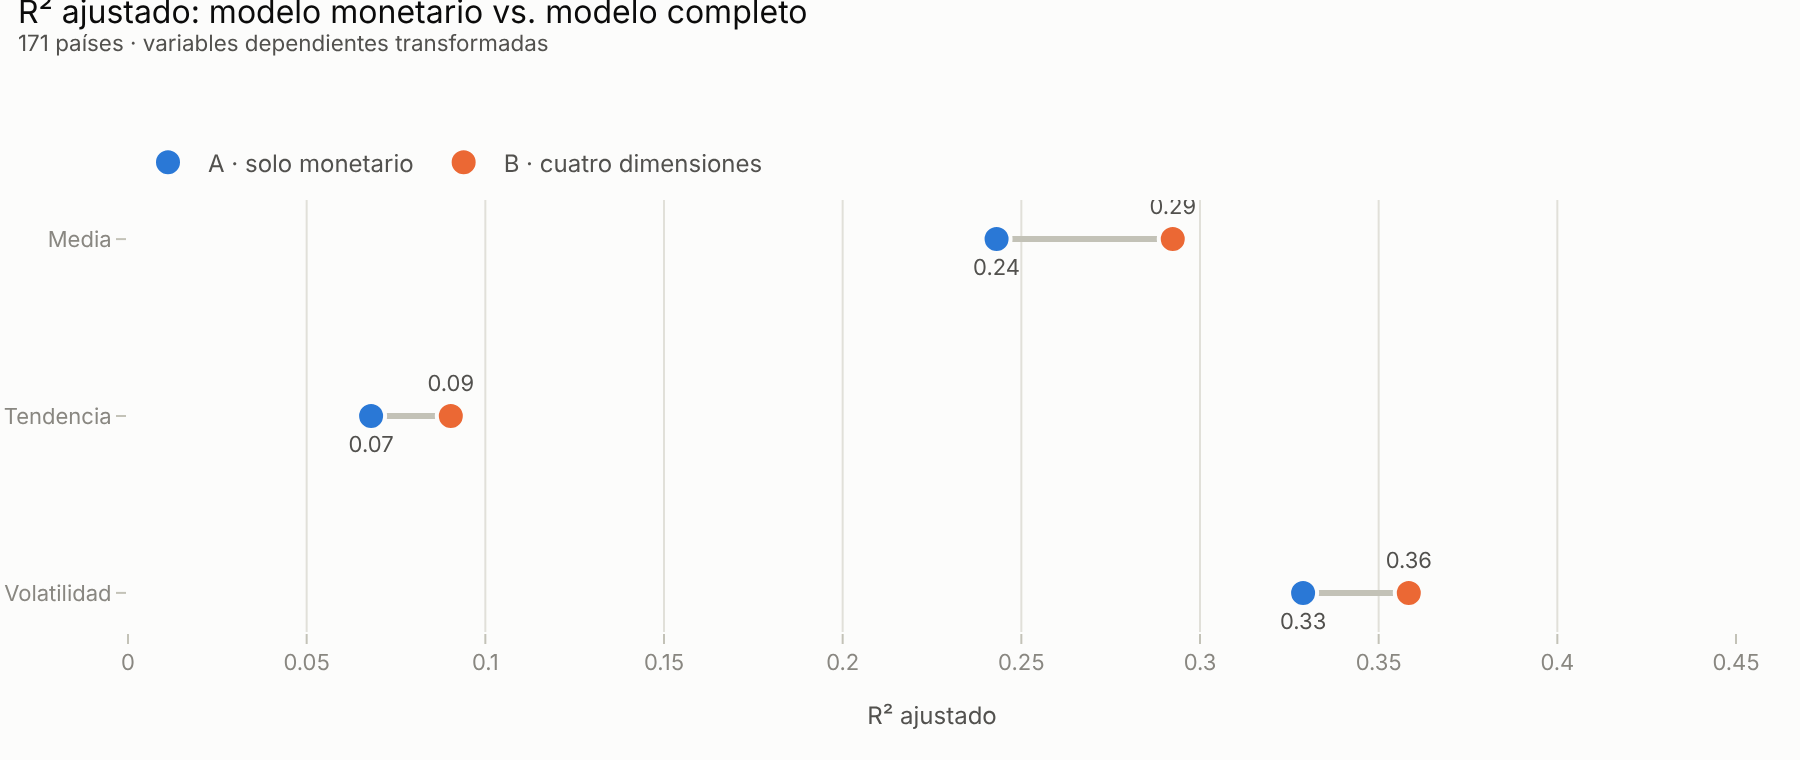

,estadistico,modelo,n,k,r2,r2adj,F_global_p,vif_max,breusch_pagan_p,shapiro_p,jarque_bera_p
0,media,A,171,2,0.252,0.243,0.000,1.001,0.063,3.900e-03,0.0
1,media,B,171,8,0.326,0.292,0.000,9.004,0.352,5.000e-04,0.0
2,tendencia,A,171,3,0.085,0.068,0.002,1.634,0.008,0.000e+00,0.0
3,tendencia,B,171,14,0.165,0.090,0.010,3.906,0.009,0.000e+00,0.0
4,volatilidad,A,171,2,0.337,0.329,0.000,1.090,0.002,0.000e+00,0.0
5,volatilidad,B,171,12,0.404,0.358,0.000,6.022,0.004,0.000e+00,0.0


In [2]:
fig = go.Figure()
for i, (stat, g) in enumerate(diag.groupby("estadistico", sort=False)):
    a, b = g.set_index("modelo").loc["A", "r2adj"], g.set_index("modelo").loc["B", "r2adj"]
    fig.add_scatter(x=[a, b], y=[STAT[stat]] * 2, mode="lines", line=dict(color="#c3c2b7", width=3), showlegend=False, hoverinfo="skip")
for j, (mod, lab) in enumerate([("A", "A · solo monetario"), ("B", "B · cuatro dimensiones")]):
    g = diag[diag["modelo"] == mod]
    fig.add_scatter(x=g["r2adj"], y=g["estadistico"].map(STAT), mode="markers+text", name=lab, text=g["r2adj"].map(lambda v: f"{v:.2f}"),
                    textposition="top center" if mod == "B" else "bottom center", textfont=dict(size=11, color=INK_SECONDARY),
                    marker=dict(size=14, color=CATEGORICAL[j], line=dict(color="#fcfcfb", width=2)), hovertemplate="%{y} · " + lab + ": R² aj. %{x:.3f}<extra></extra>")
fig.update_layout(title=subtitle("R² ajustado: modelo monetario vs. modelo completo", "171 países · variables dependientes transformadas"),
                  xaxis=dict(title="R² ajustado", range=[0, 0.45]), yaxis=dict(autorange="reversed", showgrid=False))
show(fig, "07_r2_modelos", height=380)
diag.round(4)

**Interpretación.** El perfil monetario solo (modelo A) explica una parte apreciable del nivel (R² ajustado 0,24) y de la volatilidad (0,33) de la inflación, pero casi nada de la tendencia (0,07). Agregar las tres dimensiones no monetarias sube el R² ajustado de 0,24 a **0,29 en la media**, de 0,33 a 0,36 en la volatilidad y de 0,07 a 0,09 en la tendencia. La tendencia sigue siendo en gran medida inexplicada: depende de episodios (desinflaciones, colapsos) más que de perfiles estructurales.

**Diagnósticos.** Los residuos no son normales en ningún modelo (Shapiro-Wilk p < 0,001), y hay heterocedasticidad en tendencia y volatilidad (Breusch-Pagan p < 0,01). Por eso la inferencia se apoya en HC3 y en permutación, no en el F clásico. El VIF máximo del modelo completo para la media es 9,0, en el límite habitual de 10. Es la colinealidad entre los PC1 de distintas dimensiones anticipada en el notebook 05, y vuelve imprecisos los coeficientes individuales, pero no invalida las pruebas conjuntas por bloque.

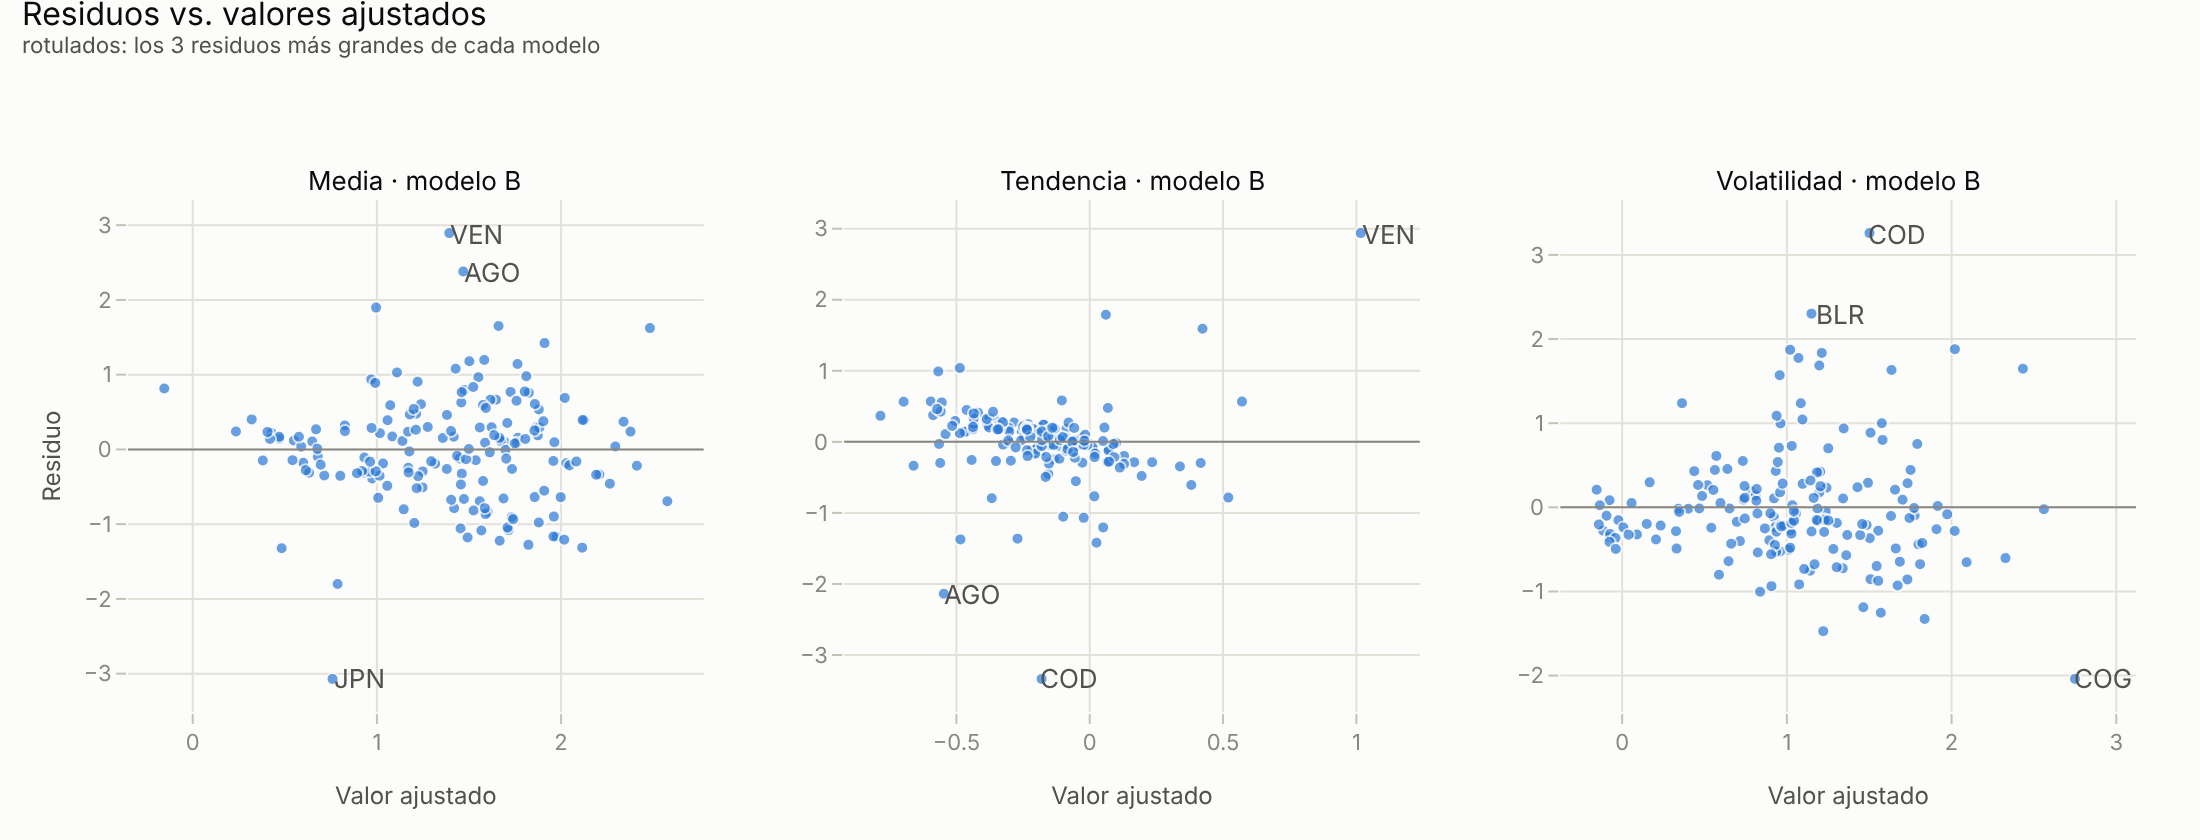

In [3]:
import statsmodels.api as sm
import pickle
from inflacion.regression import n_components_floor

pca = pickle.load(open(D / "pca_resultados.pkl", "rb"))
scores = pd.read_parquet(D / "pca_scores.parquet")
sample = pd.read_csv(D / "clusters.csv", index_col=0).index
target = pd.read_csv(D / "target_principal.csv", index_col="iso3")
TR = {"media": np.log, "tendencia": np.arcsinh, "volatilidad": np.log}
fits = {}
for stat in STAT:
    y = TR[stat](target.loc[sample, stat].dropna())
    cols = [f"{d}_{stat}__PC{i + 1}" for d in DIMENSION_COLORS for i in range(n_components_floor(pca[f"{d}_{stat}"].varianza, 0.30))]
    fits[stat] = sm.OLS(y, sm.add_constant(scores.loc[y.index, cols])).fit()

fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{v} · modelo B" for v in STAT.values()], horizontal_spacing=0.07)
for c, (stat, m) in enumerate(fits.items(), start=1):
    fig.add_scatter(x=m.fittedvalues, y=m.resid, mode="markers", marker=dict(size=6, color=CATEGORICAL[0], opacity=0.7), showlegend=False,
                    customdata=m.resid.index, hovertemplate="%{customdata}<extra></extra>", row=1, col=c)
    fig.add_hline(y=0, line=dict(color=INK_MUTED, width=1), row=1, col=c)
    big = m.resid.abs().sort_values().index[-3:]
    for iso in big:
        fig.add_annotation(x=m.fittedvalues[iso], y=m.resid[iso], text=iso, showarrow=False, xshift=14, font=dict(size=10, color=INK_SECONDARY), row=1, col=c)
fig.update_xaxes(title_text="Valor ajustado")
fig.update_yaxes(title_text="Residuo", row=1, col=1)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Residuos vs. valores ajustados", "rotulados: los 3 residuos más grandes de cada modelo"))
show(fig, "07_residuos", width=1100, height=420)

**Interpretación.** Los residuos más grandes son los casos que el EDA ya había marcado como extremos. Venezuela, Angola y Surinam tienen más inflación media que la predicha, y Japón menos (es el país con la inflación más baja del mundo en el período). Congo RD y Venezuela dominan los residuos de tendencia y volatilidad, porque sus episodios de inicio o fin de período no tienen equivalente en los perfiles estructurales. En el modelo de tendencia hay un punto con leverage de 0,86. Los resultados no dependen de él: la especificación con pendiente de Theil-Sen (notebook 08) llega a las mismas conclusiones.

## 2. Pruebas de hipótesis

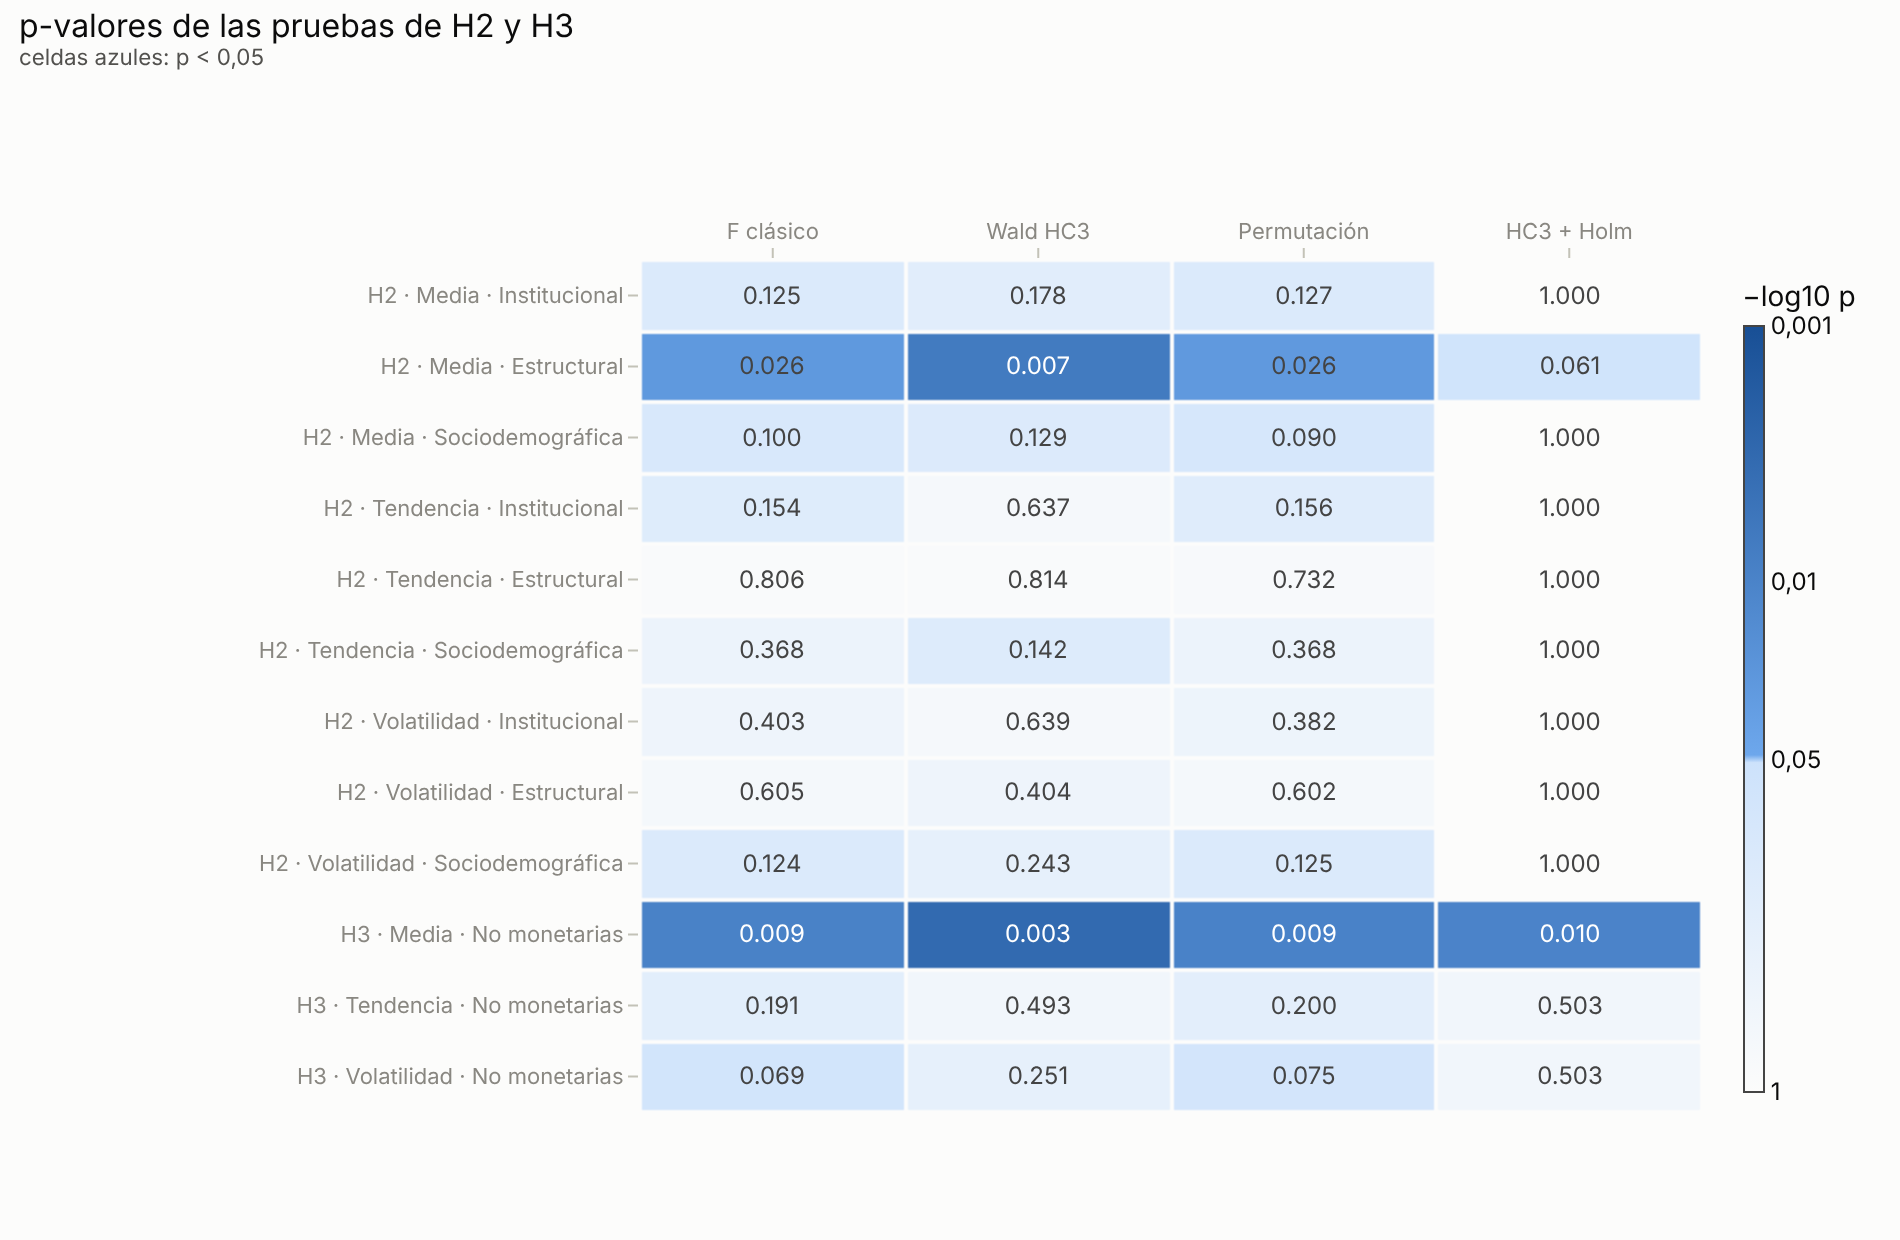

In [4]:
tests = pd.concat([h2.assign(hip="H2"), h3.assign(hip="H3")])
tests["prueba"] = tests["hip"] + " · " + tests["estadistico"].map(STAT) + " · " + tests["bloque"].map(lambda b: DIM_LABELS.get(b, "No monetarias"))
P_ = tests.set_index("prueba")[["p", "p_HC3", "p_permutacion", "p_HC3_holm"]]
P_.columns = ["F clásico", "Wald HC3", "Permutación", "HC3 + Holm"]
fig = go.Figure(go.Heatmap(z=-np.log10(P_.values), x=list(P_.columns), y=list(P_.index), zmin=0, zmax=3,
                           colorscale=[[0, "#fcfcfb"], [0.43, "#cde2fb"], [0.44, "#6da7ec"], [1, "#184f95"]],
                           text=P_.map(lambda v: f"{v:.3f}" if v >= 0.001 else "<0,001").values, texttemplate="%{text}",
                           hovertemplate="%{y} · %{x}: p = %{text}<extra></extra>", xgap=2, ygap=2,
                           colorbar=dict(title="−log10 p", tickvals=[0, 1.3, 2, 3], ticktext=["1", "0,05", "0,01", "0,001"], thickness=10)))
fig.update_layout(title=subtitle("p-valores de las pruebas de H2 y H3", "celdas azules: p < 0,05"),
                  xaxis=dict(side="top", showgrid=False), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320, t=130))
show(fig, "07_pvalores", width=950, height=620)

**Interpretación.** Solo dos pruebas dan señal consistente en las tres formas de inferencia:

- **H3 para la inflación media**: las tres dimensiones no monetarias juntas mejoran el modelo (F clásico p = 0,009, HC3 p = 0,003, permutación p = 0,009), y **sobrevive a la corrección de Holm (p = 0,010)**.
- **H2 para la dimensión estructural sobre la media**: significativa en las tres formas (p = 0,026, 0,007 y 0,026), pero **no sobrevive a Holm** (p = 0,061) entre las nueve pruebas de H2.

Ninguna dimensión no monetaria se asocia con la tendencia o la volatilidad una vez controlado el perfil monetario.

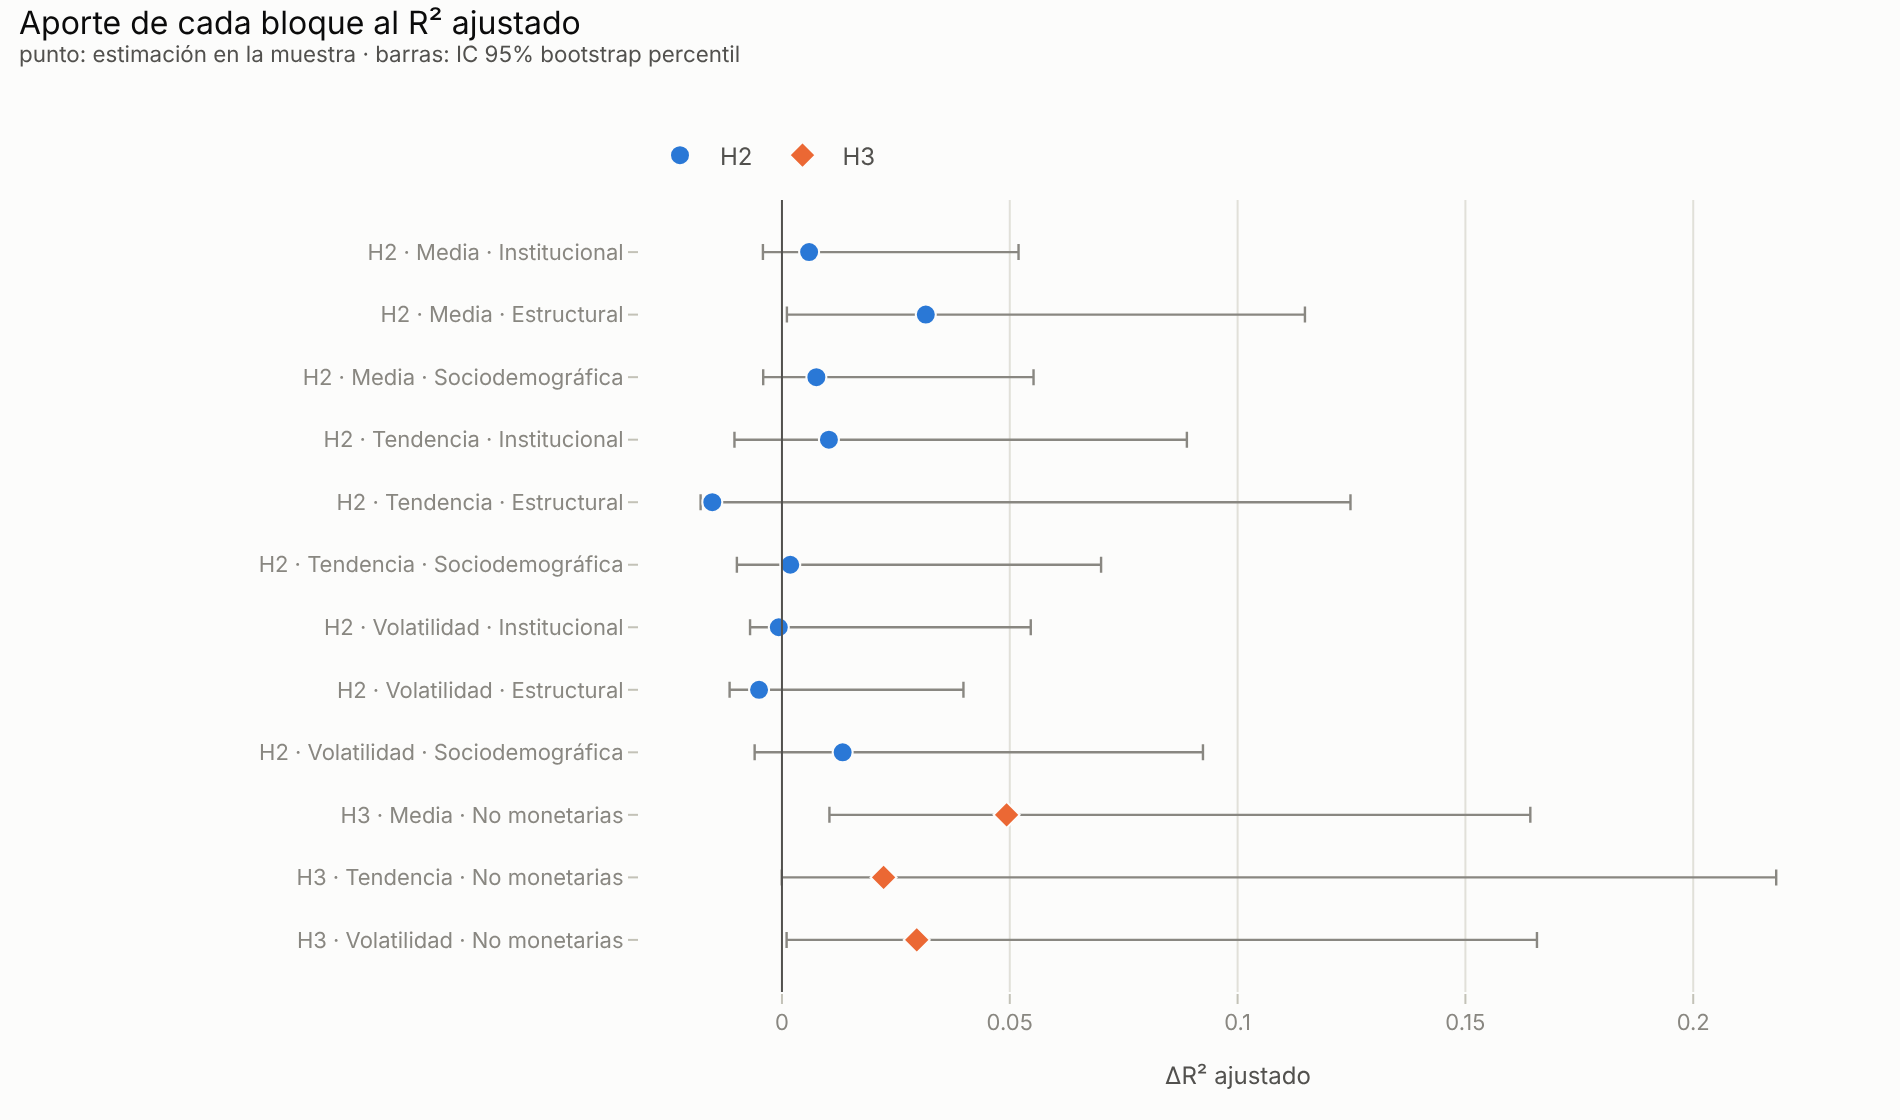

,hip,estadistico,bloque,n_comp,F,p,p_HC3,p_permutacion,p_HC3_holm,delta_r2adj,delta_ic95_inf,delta_ic95_sup,solido
0,H2,media,INSTITUCIONAL,1,2.373,0.125,0.178,0.127,1.000,6.000e-03,-0.004,0.052,False
1,H2,media,ESTRUCTURAL,4,2.852,0.026,0.007,0.026,0.061,3.160e-02,0.001,0.115,True
2,H2,media,SOCIODEMOGRAFICA,1,2.740,0.100,0.129,0.090,1.000,7.600e-03,-0.004,0.055,False
3,H2,tendencia,INSTITUCIONAL,2,1.895,0.154,0.637,0.156,1.000,1.030e-02,-0.010,0.089,False
4,H2,tendencia,ESTRUCTURAL,5,0.459,0.806,0.815,0.732,1.000,-1.530e-02,-0.018,0.125,False
5,H2,tendencia,SOCIODEMOGRAFICA,4,1.080,0.368,0.142,0.368,1.000,1.800e-03,-0.010,0.070,False
6,H2,volatilidad,INSTITUCIONAL,2,0.914,0.403,0.639,0.382,1.000,-7.000e-04,-0.007,0.055,False
7,H2,volatilidad,ESTRUCTURAL,4,0.683,0.605,0.404,0.602,1.000,-5.000e-03,-0.011,0.040,False
8,H2,volatilidad,SOCIODEMOGRAFICA,4,1.841,0.124,0.242,0.125,1.000,1.330e-02,-0.006,0.092,False
0,H3,media,NO_MONETARIAS,6,2.951,0.009,0.003,0.009,0.010,4.930e-02,0.010,0.164,True


In [5]:
t = tests.copy()
fig = go.Figure()
for i, (hip, g) in enumerate(t.groupby("hip")):
    fig.add_scatter(x=g["delta_r2adj"], y=g["prueba"], mode="markers", name=hip, marker=dict(size=10, color=CATEGORICAL[i * 1], symbol=["circle", "diamond"][i]),
                    error_x=dict(type="data", symmetric=False, array=g["delta_ic95_sup"] - g["delta_r2adj"],
                                 arrayminus=g["delta_r2adj"] - g["delta_ic95_inf"], color=INK_MUTED, thickness=1.2, width=4),
                    hovertemplate="%{y}: ΔR² aj. %{x:.3f}<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(title=subtitle("Aporte de cada bloque al R² ajustado", "punto: estimación en la muestra · barras: IC 95% bootstrap percentil"),
                  xaxis=dict(title="ΔR² ajustado", zeroline=False), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320))
show(fig, "07_delta_r2", width=950, height=560)
cols = ["hip", "estadistico", "bloque", "n_comp", "F", "p", "p_HC3", "p_permutacion", "p_HC3_holm", "delta_r2adj", "delta_ic95_inf", "delta_ic95_sup", "solido"]
tests[cols].round(4)

**Nota sobre el intervalo bootstrap.** El IC del ΔR² ajustado tiende a quedar desplazado hacia valores positivos: en las remuestras con países repetidos, agregar predictores casi siempre mejora el ajuste. Por eso el IC se usa solo como condición complementaria. La evidencia principal son las pruebas HC3 y de permutación.

## 3. ¿Qué hay detrás del resultado para la inflación media?

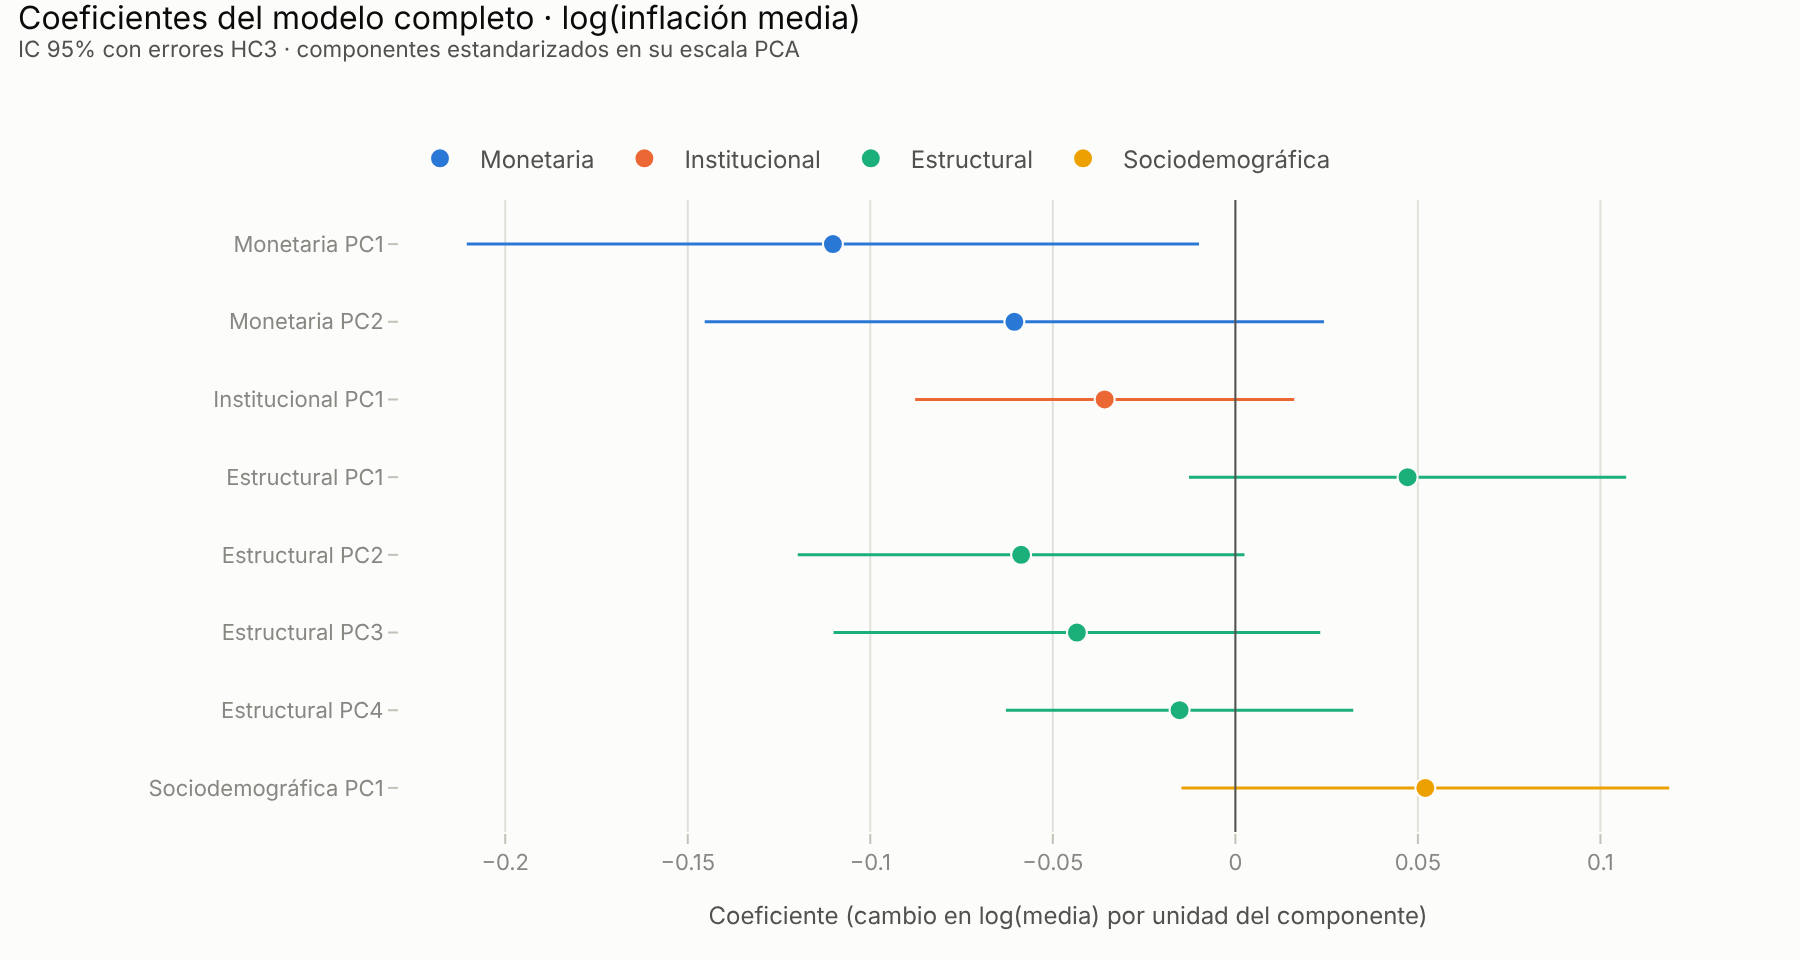

,coef,se,p
MONETARIA_media__PC1,-0.110,0.051,0.033
MONETARIA_media__PC2,-0.060,0.043,0.164
INSTITUCIONAL_media__PC1,-0.036,0.026,0.178
ESTRUCTURAL_media__PC1,0.047,0.030,0.124
ESTRUCTURAL_media__PC2,-0.059,0.031,0.062
ESTRUCTURAL_media__PC3,-0.043,0.034,0.204
ESTRUCTURAL_media__PC4,-0.015,0.024,0.530
SOCIODEMOGRAFICA_media__PC1,0.052,0.034,0.129


In [6]:
m = fits["media"]
rob = m.get_robustcov_results("HC3")
cf = pd.DataFrame({"coef": rob.params, "se": rob.bse, "p": rob.pvalues}, index=m.params.index).drop("const")
cf["dim"] = cf.index.str.split("_").str[0]
cf["lab"] = cf.index.str.replace("_media__", " ").map(lambda s: DIM_LABELS[s.split(" ")[0]] + " " + s.split(" ")[1])
fig = go.Figure()
for dim, color in DIMENSION_COLORS.items():
    g = cf[cf["dim"] == dim]
    fig.add_scatter(x=g["coef"], y=g["lab"], mode="markers", name=DIM_LABELS[dim], marker=dict(size=10, color=color),
                    error_x=dict(type="data", array=1.96 * g["se"], color=color, thickness=1.5, width=0),
                    customdata=g["p"], hovertemplate="%{y}: %{x:.3f} (p = %{customdata:.3f})<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(title=subtitle("Coeficientes del modelo completo · log(inflación media)", "IC 95% con errores HC3 · componentes estandarizados en su escala PCA"),
                  xaxis_title="Coeficiente (cambio en log(media) por unidad del componente)", yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=200))
show(fig, "07_coeficientes_media", width=900, height=480)
cf[["coef", "se", "p"]].round(4)

**Interpretación.** Ningún componente estructural es significativo por separado: el aporte de la dimensión es **conjunto** y se reparte entre varios ejes, consistente con la colinealidad del modelo. El componente con señal más clara es el PC2 estructural (p = 0,06; ver cargas abajo), que contrapone las economías de servicios, turismo y exportación de alimentos (menor inflación) a las industriales y de generación con petróleo. El PC1 monetario (capacidad fiscal y profundidad financiera) es el único coeficiente individual significativo (−0,11, p = 0,03): más profundidad financiera, menos inflación media. Los coeficientes no deben leerse como efectos causales, porque cada componente resume decenas de indicadores correlacionados entre sí.

In [7]:
meta = pd.concat([pd.read_csv(Paths.raw / "wdi" / "wdi_metadata_20261111.csv"),
                  pd.read_csv(Paths.raw / "vdem" / "vdem_79_metadata_v16.csv")]).drop_duplicates("codigo").set_index("codigo")["nombre_indicador"]
meta["hh_market_concentration"] = "Export market concentration (HHI)"
for k in range(1, 5):
    L = pca["ESTRUCTURAL_media"].cargas[f"ESTRUCTURAL_media__PC{k}"]
    top = L.reindex(L.abs().sort_values(ascending=False).index[:5])
    print(f"ESTRUCTURAL_media PC{k} ({pca['ESTRUCTURAL_media'].varianza[k - 1]:.1%}) coef {cf.loc[f'ESTRUCTURAL_media__PC{k}', 'coef']:+.3f} (p={cf.loc[f'ESTRUCTURAL_media__PC{k}', 'p']:.3f}):")
    for i, v in top.items():
        print(f"    {v:+.2f}  {meta.get(i.rsplit('__', 1)[0], i)[:70]}")

ESTRUCTURAL_media PC1 (15.5%) coef +0.047 (p=0.125):
    +0.82  Agriculture, forestry, and fishing, value added (% of GDP)
    -0.81  Wage and salaried workers, male (% of male employment) (modeled ILO es
    +0.72  Exclusion by Socio-Economic Group
    -0.69  Medium and high-tech manufacturing value added (% manufacturing value 
    +0.69  External health expenditure (% of current health expenditure)
ESTRUCTURAL_media PC2 (7.3%) coef -0.059 (p=0.062):
    +0.73  International tourism, receipts (% of total exports)
    -0.70  Industry (including construction), value added (% of GDP)
    +0.60  Food exports (% of merchandise exports)
    +0.58  Services, value added (% of GDP)
    +0.55  Electricity production from oil sources (% of total)
ESTRUCTURAL_media PC3 (6.1%) coef -0.043 (p=0.204):
    +0.56  Electricity production from oil, gas and coal sources (% of total)
    +0.50  Adjusted savings: energy depletion (% of GNI)
    +0.48  Merchandise exports to low- and middle-income economi

## 4. Síntesis

In [8]:
def verdict(r):
    if r["solido"] and r["p_HC3_holm"] < 0.05:
        return "Sólido (sobrevive a Holm)"
    if r["solido"]:
        return "Sólido sin corrección"
    if min(r["p"], r["p_HC3"], r["p_permutacion"]) < 0.05:
        return "Indicio (no robusto)"
    return "Sin evidencia"
tab = tests.assign(veredicto=tests.apply(verdict, axis=1))[["hip", "estadistico", "bloque", "delta_r2adj", "p_HC3", "p_permutacion", "p_HC3_holm", "veredicto"]]
tab.round(4)

,hip,estadistico,bloque,delta_r2adj,p_HC3,p_permutacion,p_HC3_holm,veredicto
0,H2,media,INSTITUCIONAL,6.000e-03,0.178,0.127,1.000,Sin evidencia
1,H2,media,ESTRUCTURAL,3.160e-02,0.007,0.026,0.061,Sólido sin corrección
2,H2,media,SOCIODEMOGRAFICA,7.600e-03,0.129,0.090,1.000,Sin evidencia
3,H2,tendencia,INSTITUCIONAL,1.030e-02,0.637,0.156,1.000,Sin evidencia
4,H2,tendencia,ESTRUCTURAL,-1.530e-02,0.815,0.732,1.000,Sin evidencia
5,H2,tendencia,SOCIODEMOGRAFICA,1.800e-03,0.142,0.368,1.000,Sin evidencia
6,H2,volatilidad,INSTITUCIONAL,-7.000e-04,0.639,0.382,1.000,Sin evidencia
7,H2,volatilidad,ESTRUCTURAL,-5.000e-03,0.404,0.602,1.000,Sin evidencia
8,H2,volatilidad,SOCIODEMOGRAFICA,1.330e-02,0.242,0.125,1.000,Sin evidencia
0,H3,media,NO_MONETARIAS,4.930e-02,0.003,0.009,0.010,Sólido (sobrevive a Holm)


## Conclusión de H2 y H3

| | Media | Tendencia | Volatilidad |
|---|---|---|---|
| **H3** (las tres dimensiones no monetarias juntas) | **Confirmada**: R² aj. 0,24 → 0,29; robusta a HC3, permutación y Holm | No confirmada | No confirmada (p ≈ 0,07) |
| **H2 · estructural** | Evidencia moderada: sólida en las tres pruebas, no sobrevive a Holm (p = 0,061); indicio en 2 de 3 especificaciones alternativas | Sin evidencia | Sin evidencia |
| **H2 · institucional** | Sin evidencia | Sin evidencia | Sin evidencia |
| **H2 · sociodemográfica** | Sin evidencia (p ≈ 0,09-0,13) | Sin evidencia | Sin evidencia |

**Lectura.** Más allá del perfil monetario-fiscal, las configuraciones no monetarias aportan información sobre **el nivel** de la inflación de un país, pero no sobre su dirección (tendencia) ni sobre su estabilidad alrededor de esa dirección (volatilidad). Ninguna dimensión aislada alcanza a explicar ese aporte con robustez plena. El aporte es conjunto, compatible con el planteo multicausal de la tesis: lo que cuenta es la combinación de dimensiones y no una en particular.

**Diferencias con la tesis (versión 1).** En la tesis, H3 se confirmaba para la volatilidad y H2 no encontraba ninguna dimensión robusta. Con el pipeline corregido (sin medidas de precios entre los predictores, sin duplicados ni niveles absolutos y con log(media) como transformación), la mejora conjunta robusta aparece en la **media** y no en la volatilidad, y la dimensión estructural muestra evidencia moderada. El notebook 08 evalúa la robustez de estas conclusiones.